# Proyecto 7 - Explorando factores de comportamiento en NovaRetail+


NovaRetail+ es una plataforma de comercio electrónico en Latinoamérica con millones de usuarios.

Para el cierre de 2024, el equipo de **Crecimiento y retención** tiene como objetivo responder:

**¿Qué factores del comportamiento del cliente están más fuertemente asociados con el ingreso anual generado?**

> Este proyecto es un análisis **correlacional** (exploratorio).  
> **Correlación ≠ causalidad.**

## Sección 1 - Cargar y explorar el dataset

En esta sección validamos:
- que el dataset cargue correctamente
- tipos de datos
- valores faltantes / rangos generales

Antes de correlacionar, primero entendemos el “terreno”.

In [1]:
# Importar librerías
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

### Cargar Dataset

In [2]:
# Cargar el dataset y explorar datos
df = pd.read_csv('/datasets/novaretail_comportamiento_clientes_2024.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  float64
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(5), int64(4), object(3)
memory usage: 1.4+ MB


#### Descripción del conjunto de datos

El dataset contiene las siguientes columnas:

- `id_cliente` — Identificador único del cliente.
- `edad` — Edad del cliente.
- `nivel_ingreso` — Ingreso anual estimado del cliente.
- `visitas_mes` — Número de visitas a la aplicación o sitio web durante el mes.
- `compras_mes` — Número de compras realizadas en el mes.
- `gasto_publicidad_dirigida` — Gasto en anuncios asignado al usuario.
- `satisfaccion` — Calificación de satisfacción del cliente en una escala del 1 al 5.
- `miembro_premium` — Indica si el cliente tiene suscripción premium (1) o no (0).
- `abandono` — Indica si el cliente abandonó la plataforma (1) o no (0).
- `tipo_dispositivo` — Tipo de dispositivo utilizado por el cliente (móvil, escritorio o tablet).
- `region` — Región geográfica del cliente (norte, sur, oeste o este).
- `ingreso_anual` — Ingreso anual generado por el cliente para la empresa.

La métrica principal de análisis es `ingreso_anual`, utilizada para evaluar el impacto económico de los clientes.


In [3]:
# mostrar las primeras 5 filas
df.head()

,id_cliente,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,tipo_dispositivo,region,ingreso_anual
0,CL-100000,44.0,28565.77,9,1,31.36,3.9,0,0,móvil,norte,23.22
1,CL-100001,36.0,29673.44,11,3,24.66,3.7,0,0,tablet,sur,93.47
2,CL-100002,46.0,30642.95,9,0,0.00,2.9,0,0,móvil,este,0.00
3,CL-100003,56.0,39468.61,8,0,6.81,3.1,0,0,móvil,este,0.00
4,CL-100004,35.0,22527.83,9,2,26.49,2.3,0,0,móvil,sur,33.76


## Sección 2 - Preparar datos y documentar supuestos

### Exploración y Limpieza

#### Exploración inicial de los datos
El conjunto de datos contiene **15,000 registros** y **12 columnas**, sin valores nulos.

**Variables numéricas**  
Se identifican las siguientes columnas numéricas:
- `edad`
- `nivel_ingreso`
- `visitas_mes`
- `compras_mes`
- `gasto_publicidad_dirigida`
- `satisfaccion`
- `ingreso_anual`

La mayoría de estas variables presentan tipos de datos adecuados. Sin embargo se ajustaran algunas variables para corregir su tipo

| Variable | Tipo actual | Tipo esperado para el análisis | Razón |
|-----------|------------|-------------------------------|--------|
| edad | float64 | int64 | La edad normalmente se expresa en años completos y no debería contener valores decimales. |

**Variables binarias**  
Las siguientes columnas representan variables binarias:
- `miembro_premium`
- `abandono`

Ambas están codificadas como 0 y 1, **no requieren transformación adicional**.

**Variables categóricas**  
Se identifican las siguientes columnas categóricas:
- `id_cliente`
- `tipo_dispositivo`
- `region`

Estas variables están correctamente definidas y no requieren transformación adicional.

In [4]:
# Corregir el tipo de dato
df['edad'] = df['edad'].astype('int64')

In [5]:
# verificar cambios
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  int64  
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(4), int64(5), object(3)
memory usage: 1.4+ MB


#### Explorar variables numéricas

In [6]:
# Estadísticas descriptivas de variables numéricas
# Definir variables numericas
numeric_cols = df.select_dtypes(include='number').columns
df[numeric_cols].describe()

,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,ingreso_anual
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,38.262400,30019.704782,10.029000,1.206467,20.149301,3.603693,0.139267,0.150733,36.594180
std,11.492378,9833.166305,3.158189,1.105284,10.880724,0.685300,0.346236,0.357801,34.484888
min,18.000000,8000.000000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000
25%,30.000000,23127.097500,8.000000,0.000000,12.310000,3.100000,0.000000,0.000000,0.000000
50%,38.000000,30023.745000,10.000000,1.000000,19.730000,3.600000,0.000000,0.000000,30.705000
75%,46.000000,36768.440000,12.000000,2.000000,27.292500,4.100000,0.000000,0.000000,58.220000
max,75.000000,74790.840000,25.000000,8.000000,75.510000,5.000000,1.000000,1.000000,244.690000


### Observaciones de las variables numéricas

Tras revisar las estadísticas descriptivas de las variables numéricas, se identifican los siguientes hallazgos:

- **No se observan valores ausentes**, ya que todas las variables cuentan con 15.000 registros.

- La variable **edad** presenta valores entre **18 y 75 años**, con una media de **38,26 años** y una mediana de **38 años**. La similitud entre ambas medidas sugiere una distribución relativamente equilibrada.

- El **nivel de ingreso** muestra una media de **30.019,70** y una mediana de **30.023,75**, lo que indica una distribución bastante simétrica. Los ingresos presentan una variabilidad moderada dentro de la muestra.

- Los clientes realizan en promedio **10 visitas mensuales** a la plataforma. El 50% de los usuarios registra entre **8 y 12 visitas al mes**, lo que refleja un nivel de interacción relativamente estable.

- La variable **compras_mes** presenta una media de **1,21 compras mensuales**, donde el **25%** de clientes **no hicieron compras en el mes**. Esto es considerablemente menor que el promedio de visitas. Esto sugiere que no todas las visitas terminan en una compra y podría existir margen para mejorar la conversión.

- El **gasto en publicidad dirigida** presenta una media de **20,15 unidades monetarias** y una desviación estándar de **10,88**, indicando una variabilidad moderada en la inversión publicitaria realizada sobre cada cliente.

- La **satisfacción** de los clientes tiene una media de **3,60 sobre 5**, con una mediana prácticamente idéntica. Esto indica una percepción generalmente positiva de la experiencia ofrecida por la plataforma.

- Aproximadamente el **13,9% de los clientes** son miembros premium, mientras que el **86,1%** restante pertenece al plan estándar.

- La tasa de **abandono** es cercana al **15,1%**, lo que indica que la mayoría de los clientes permanece activa, aunque existe un segmento relevante de usuarios que deja de utilizar la plataforma.

- La variable objetivo **ingreso_anual** presenta una media de **36,59** y una mediana de **30,71**. La diferencia entre ambas métricas, junto con un valor máximo de **244,69**, sugiere la posible existencia de clientes con un valor económico significativamente superior al resto de la población.

### Hipótesis preliminares para el análisis

A partir de estas estadísticas descriptivas, resulta razonable explorar las siguientes relaciones:

- El nivel de ingreso podría estar asociado con un mayor ingreso anual para la empresa.
- Los clientes premium podrían generar mayores ingresos que los clientes estándar.
- Una mayor frecuencia de visitas y compras podría traducirse en un incremento del ingreso anual.
- Los clientes con mayores niveles de satisfacción podrían presentar menores tasas de abandono.
- El abandono podría tener un impacto negativo sobre el ingreso anual generado por los clientes.

#### Explorar variables binarias

In [7]:
# Verificar que cada columna binaria tenga únicamente dos valores posibles
for col in ['miembro_premium', 'abandono']:
    print(f'\n{"="*40}')
    print(f'Variable: {col}')
    print(f'{"="*40}')
    
    print('Valores únicos:', sorted(df[col].unique()))
    print('Número de categorías:', df[col].nunique())
    
    print('\nFrecuencia de cada valor:')
    print(df[col].value_counts().sort_index())



Variable: miembro_premium
Valores únicos: [0, 1]
Número de categorías: 2

Frecuencia de cada valor:
0    12911
1     2089
Name: miembro_premium, dtype: int64

Variable: abandono
Valores únicos: [0, 1]
Número de categorías: 2

Frecuencia de cada valor:
0    12739
1     2261
Name: abandono, dtype: int64


### Análisis exploratorio de variables binarias

Las variables `miembro_premium` y `abandono` fueron revisadas para verificar que únicamente contienen dos categorías posibles. En ambos casos se confirmó la presencia exclusiva de los valores **0** y **1**, por lo que representan correctamente variables binarias.

#### Miembro premium

- La variable `miembro_premium` contiene únicamente los valores 0 y 1.
- Se identificaron **12.911 clientes no premium** (0) y **2.089 clientes premium** (1).
- Esto significa que aproximadamente el **86,07%** de los clientes pertenece al plan estándar, mientras que el **13,93%** cuenta con una membresía premium.
- La distribución muestra un claro predominio de clientes no premium dentro de la plataforma.

#### Abandono

- La variable `abandono` también contiene únicamente los valores 0 y 1.
- Se identificaron **12.739 clientes activos** (0) y **2.261 clientes que abandonaron la plataforma** (1).
- La tasa de abandono observada es de aproximadamente **15,07%**.
- Aunque la mayoría de los clientes permanece activa, el porcentaje de abandono es lo suficientemente significativo como para justificar un análisis más profundo de los factores que pueden estar influyéndolo.

#### Explorar variables categóricas

In [8]:
# Verificar el número de valores únicos por variable categórica
categorical_cols = [
    'tipo_dispositivo',
    'region'
]

df[categorical_cols].describe()


,tipo_dispositivo,region
count,15000,15000
unique,3,4
top,móvil,norte
freq,9818,4395


In [9]:
# Explorar variables categóricas y cómo se distribuyen
for col in categorical_cols:
    print(f'\n{"="*50}')
    print(f'Variable: {col}')
    print(f'{"="*50}')

    print('Número de categorías:', df[col].nunique())

    summary = pd.DataFrame({
        'Frecuencia': df[col].value_counts(),
        'Porcentaje (%)': round(df[col].value_counts(normalize=True) * 100, 2)
    })

    print('\nDistribución:')
    display(summary)



Variable: tipo_dispositivo
Número de categorías: 3

Distribución:


,Frecuencia,Porcentaje (%)
móvil,9818,65.45
escritorio,3720,24.80
tablet,1462,9.75



Variable: region
Número de categorías: 4

Distribución:


,Frecuencia,Porcentaje (%)
norte,4395,29.30
oeste,3810,25.40
sur,3726,24.84
este,3069,20.46


## Análisis de variables categóricas

### 📱 Tipo de dispositivo

| Categoría | Clientes | Participación |
|------------|------------|------------|
| Móvil | 9.818 | 65,45% |
| Escritorio | 3.720 | 24,80% |
| Tablet | 1.462 | 9,75% |

#### Hallazgos principales

✅ El dispositivo móvil es el más utilizado por los clientes, representando casi dos tercios de la muestra.

✅ Los usuarios de escritorio constituyen aproximadamente una cuarta parte de los registros.

✅ Las tabletas son el dispositivo menos frecuente, con menos del 10% de participación.

---

### 🌎 Región

| Región | Clientes | Participación |
|---------|---------:|---------:|
| Norte | 4.395 | 29,30% |
| Oeste | 3.810 | 25,40% |
| Sur | 3.726 | 24,84% |
| Este | 3.069 | 20,46% |

#### Hallazgos principales

✅ La distribución regional es relativamente equilibrada.

✅ La región Norte concentra la mayor cantidad de clientes.

✅ Ninguna región domina excesivamente la muestra.

---

### 📌 Resumen general

- El dispositivo móvil es el canal predominante dentro de la muestra.
- La distribución geográfica es suficientemente equilibrada para realizar comparaciones regionales.
- El tipo de dispositivo y la región serán variables relevantes para los análisis posteriores.
- En esta etapa únicamente se describen distribuciones observadas; no es posible establecer relaciones causales entre variables.

### Supuestos

- El análisis se realiza utilizando **todo el conjunto de datos disponible**.
- Los datos no presentan errores y están correctamente tipificados.
- Se utilizan distintos coeficientes según el tipo de variable:
  - **Pearson** asume relaciones lineales entre variables numéricas.
  - **Spearman** evalúa relaciones monótonas y no requiere normalidad.
  - **Punto biserial** se usa para relaciones numérica–binaria.
  - **Cramér (V)** se usa para asociaciones entre variables categóricas.

**Supuesto central:**  
Este análisis identifica relaciones entre variables o segmentos, pero no prueba causalidad.

## Sección 3 - Visualización de relaciones

Observamos cómo se relacionan las variables numéricas.

### Heatmap

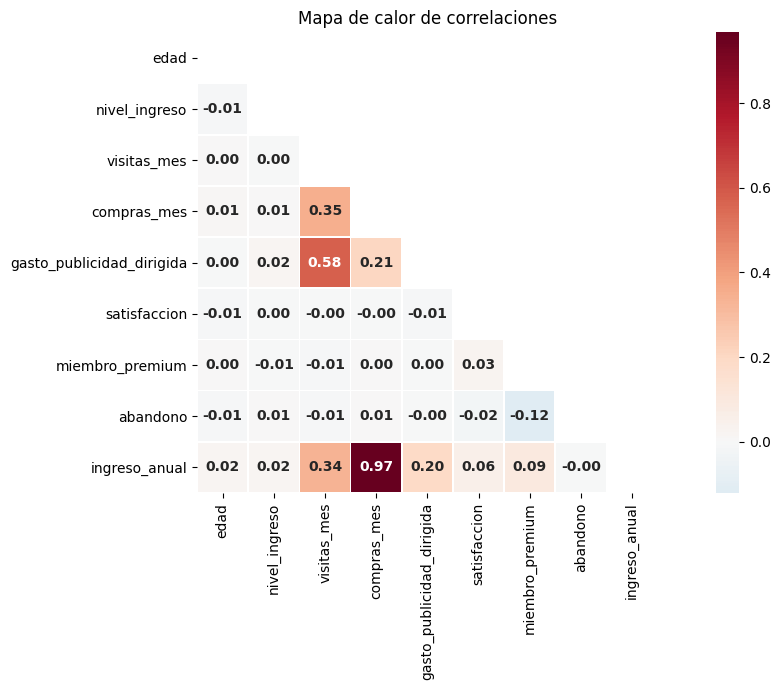

In [10]:
# Visualizar la matriz de correlación para identificar relaciones
corr_matrix = df[numeric_cols].corr()

plt.figure(figsize=(12, 7))

mask = np.triu(np.ones_like(df[numeric_cols].corr(), dtype=bool))

sns.heatmap(
    df[numeric_cols].corr(),
    mask=mask,
    annot=True,
    fmt='.2f',
    cmap='RdBu_r',
    center=0,
    square=True,
    linewidths=0.5,
    annot_kws={"size":10, "weight":"bold"}
)

plt.title('Mapa de calor de correlaciones')
plt.tight_layout()
plt.show()

## Diagnóstico de correlaciones

El mapa de calor permite identificar qué variables presentan movimientos similares y cuáles parecen tener poca o ninguna relación lineal.

### 🔍 Hallazgos generales

✅ La mayoría de las variables muestran correlaciones bajas o cercanas a cero.

✅ No se observan relaciones fuertes entre variables demográficas (`edad`, `nivel_ingreso`) y el resto de los indicadores del negocio.

✅ Las relaciones más relevantes se concentran en variables asociadas al comportamiento de compra y la interacción con la plataforma.

✅ No se identifican grupos amplios de variables altamente correlacionadas, lo que sugiere que cada variable aporta información relativamente diferente al análisis.

---

### 📈 Relaciones más destacadas

#### Compras mensuales e ingreso anual
**Correlación: 0.97**

- Es la relación más fuerte observada en todo el conjunto de datos.
- Los clientes con una mayor cantidad de compras mensuales tienden a registrar mayores valores de ingreso anual.
- Esta variable parece estar estrechamente vinculada al desempeño económico de los clientes dentro de la plataforma.

#### Visitas mensuales y gasto en publicidad dirigida
**Correlación: 0.58**

- Se observa una relación positiva moderada.
- Los niveles más altos de visitas suelen aparecer junto con mayores valores de gasto en publicidad dirigida.
- Esta asociación sugiere que ambas variables comparten patrones de comportamiento similares dentro de la muestra.

#### Visitas mensuales y compras mensuales
**Correlación: 0.35**

- Existe una relación positiva moderada.
- Los clientes que visitan la plataforma con mayor frecuencia también suelen registrar una mayor cantidad de compras.
- Aunque la asociación no es especialmente fuerte, sí resulta visible dentro del conjunto de datos.

---

## 💰 Diagnóstico específico de ingreso_anual

Dado que `ingreso_anual` representa una de las variables más importantes para el negocio, resulta especialmente relevante identificar qué variables presentan las asociaciones más altas con ella.

| Variable | Correlación con ingreso_anual |
|-----------|-----------:|
| compras_mes | **0.97** |
| visitas_mes | **0.34** |
| gasto_publicidad_dirigida | **0.20** |
| miembro_premium | **0.09** |
| satisfaccion | **0.06** |
| nivel_ingreso | **0.02** |
| edad | **0.02** |
| abandono | **-0.00** |

### Variables con mayor asociación

#### 🛒 compras_mes (0.97)

- Presenta, con diferencia, la asociación más alta con el ingreso anual.
- Los mayores ingresos anuales tienden a encontrarse entre los clientes que realizan más compras al mes.
- Esta variable destaca claramente sobre el resto de los indicadores analizados.

#### 👀 visitas_mes (0.34)

- Muestra una asociación positiva moderada con el ingreso anual.
- Los clientes más activos dentro de la plataforma suelen registrar ingresos anuales más elevados.
- La intensidad de esta relación es considerablemente menor que la observada en `compras_mes`, aunque sigue siendo relevante.

#### 🎯 gasto_publicidad_dirigida (0.20)

- Presenta una asociación positiva débil a moderada.
- Los valores más altos de ingreso anual tienden a coincidir con mayores niveles de gasto publicitario.
- La relación existe, aunque se observa con una intensidad limitada.

---

### Variables con baja asociación

#### ⭐ satisfaccion (0.06)

- La satisfacción presenta una relación positiva muy débil con el ingreso anual.
- No se aprecia una asociación lineal importante entre ambos indicadores.

#### 👑 miembro_premium (0.09)

- La pertenencia al programa premium muestra una asociación positiva ligera con el ingreso anual.
- La diferencia observada es pequeña en comparación con otras variables.

#### 👤 edad (0.02) y nivel_ingreso (0.02)

- Prácticamente no muestran relación lineal con el ingreso anual.
- En la muestra analizada, estas variables parecen aportar poca información sobre las variaciones del ingreso anual.

#### 🚪 abandono (-0.00)

- No se observa relación lineal entre abandono e ingreso anual.
- El coeficiente es prácticamente nulo.


### Scatterplot general

### Selección de variables para el análisis de dispersión

Aunque una matriz de dispersión completa permite examinar todas las relaciones posibles entre las variables numéricas, no se consideró necesario incluirla en este análisis. El mapa de calor de correlaciones mostró que la mayoría de los coeficientes se encuentran muy próximos a cero, lo que indica relaciones débiles o inexistentes entre gran parte de las variables.

Considerando que el conjunto de datos contiene nueve variables numéricas, una matriz completa generaría 36 comparaciones bivariadas. En estas condiciones, la mayoría de los gráficos aportarían poca información adicional y aumentarían el ruido visual, dificultando la identificación de patrones realmente relevantes.

Por esta razón, se optó por realizar una matriz de dispersión reducida, enfocada únicamente en las variables que presentaron las correlaciones más significativas en el análisis previo. Este enfoque permite validar visualmente las relaciones identificadas en el mapa de calor, detectar posibles valores atípicos y evaluar si las asociaciones observadas mantienen una tendencia consistente en los datos.

Las correlaciones más relevantes identificadas fueron:

- **compras_mes ↔ ingreso_anual:** 0.97
- **visitas_mes ↔ gasto_publicidad_dirigida:** 0.58
- **visitas_mes ↔ compras_mes:** 0.35
- **visitas_mes ↔ ingreso_anual:** 0.34
- **compras_mes ↔ gasto_publicidad_dirigida:** 0.21

A partir de estos resultados, la matriz de dispersión se construyó utilizando las variables **visitas_mes**, **compras_mes**, **gasto_publicidad_dirigida** e **ingreso_anual**, ya que concentran las asociaciones más relevantes del conjunto de datos y permiten un análisis visual más eficiente y enfocado.

### Scatterplot para pares clave

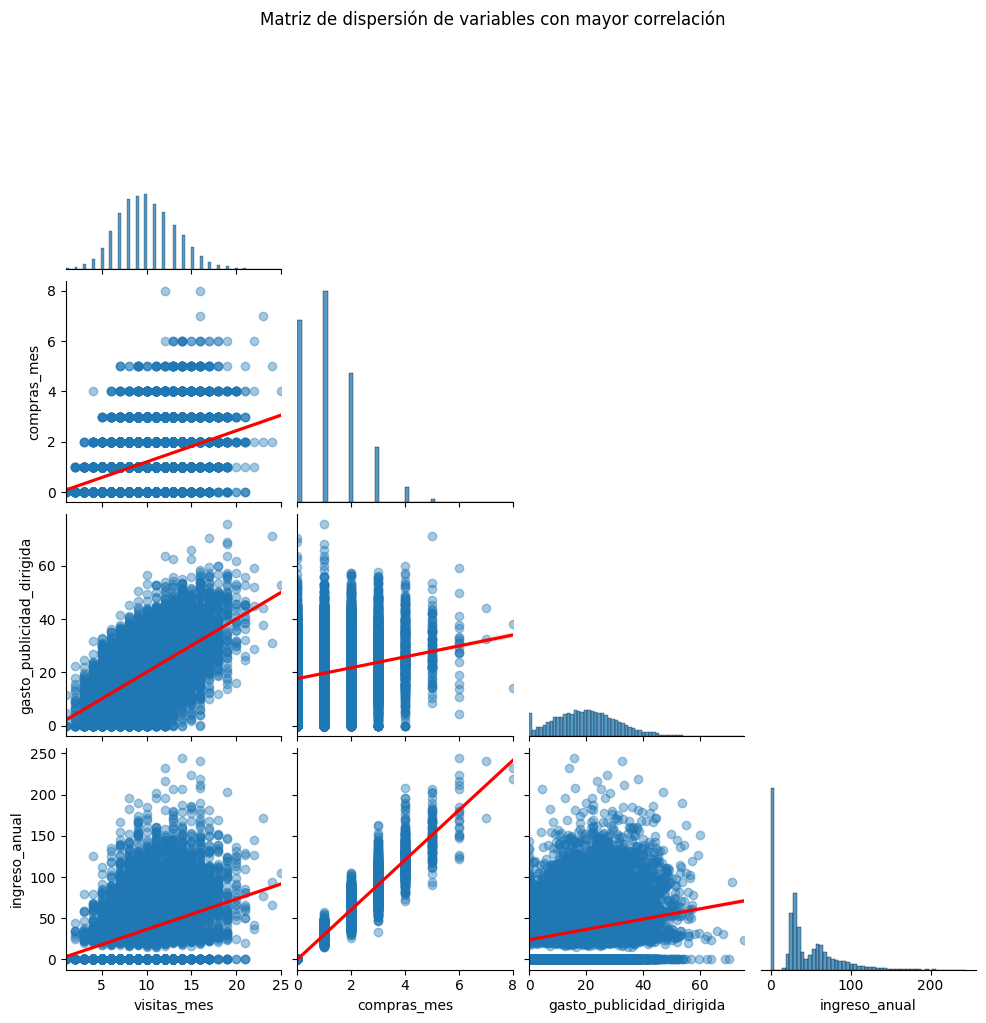

In [11]:
# Visualizar pares de variables con relaciones moderadas o fuertes
cols_scater = [
    'visitas_mes',
    'compras_mes',
    'gasto_publicidad_dirigida',
    'ingreso_anual'
]

sns.pairplot(
    df[cols_scater],
    corner=True,
    kind='reg',
    plot_kws={
        'scatter_kws': {'alpha': 0.4},
        'line_kws': {'color': 'red'}
    }
)

plt.suptitle(
    'Matriz de dispersión de variables con mayor correlación',
    y=1.02
)

plt.show()

### Observaciones iniciales (Scatterplots)

**visitas_mes vs compras_mes**

- **Dirección:** Positiva. A medida que aumenta el número de visitas mensuales, también tiende a incrementarse el número de compras realizadas por los clientes.
- **Dispersión:** Media. Aunque existe una tendencia ascendente, los puntos presentan una dispersión considerable alrededor de la línea de tendencia.
- **Outliers:** No se observan valores atípicos extremos que alteren significativamente el patrón general.
- **Posible colinealidad:** Baja. La correlación observada (0.35) indica una asociación moderada, insuficiente para sugerir problemas de colinealidad.

---

**visitas_mes vs gasto_publicidad_dirigida**

- **Dirección:** Positiva. Los clientes con más visitas tienden a presentar mayores niveles de inversión publicitaria dirigida.
- **Dispersión:** Media. Se aprecia una tendencia clara, aunque con una variabilidad importante en los valores observados.
- **Outliers:** Existen algunos registros con gastos publicitarios superiores al resto de observaciones, pero no parecen dominar la relación.
- **Posible colinealidad:** Moderada. La correlación (0.58) muestra una relación apreciable, aunque no lo suficientemente alta como para representar un problema de colinealidad.

---

**compras_mes vs ingreso_anual**

- **Dirección:** Fuertemente positiva. Un aumento en la cantidad de compras mensuales se asocia con mayores ingresos anuales.
- **Dispersión:** Baja. Los puntos siguen una trayectoria ascendente claramente definida.
- **Outliers:** Se observan algunos valores altos de ingreso anual, pero siguen la tendencia general de la relación.
- **Posible colinealidad:** Alta. La correlación de 0.97 indica una relación extremadamente fuerte entre ambas variables, por lo que podría existir multicolinealidad si se utilizan simultáneamente en modelos predictivos.

---

**gasto_publicidad_dirigida vs ingreso_anual**

- **Dirección:** Positiva. A mayores niveles de gasto publicitario dirigido se observa una tendencia hacia mayores ingresos anuales.
- **Dispersión:** Alta. La nube de puntos es considerablemente dispersa, lo que indica que otros factores también influyen en el ingreso anual.
- **Outliers:** Se identifican algunos clientes con ingresos anuales significativamente superiores al promedio.
- **Posible colinealidad:** Baja. La relación observada no es lo suficientemente fuerte para sugerir problemas de colinealidad.

## Sección 4 - Coeficientes de correlación y evidencia numérica

En esta sección, se reportan coeficientes que respaldan los patrones
observados visualmente, utilizando el método adecuado según el tipo
de variables.

### Pearson / Spearman

In [12]:
# Calcular correlación entre variables relevantes
# Variables seleccionadas
variables_relevantes = [
    'visitas_mes',
    'compras_mes',
    'gasto_publicidad_dirigida',
    'ingreso_anual'
]

# Matriz de correlación de Pearson
corr_pearson = df[variables_relevantes].corr(method='pearson')

print('Correlación de Pearson')
display(corr_pearson.round(2))

Correlación de Pearson


,visitas_mes,compras_mes,gasto_publicidad_dirigida,ingreso_anual
visitas_mes,1.00,0.35,0.58,0.34
compras_mes,0.35,1.00,0.21,0.97
gasto_publicidad_dirigida,0.58,0.21,1.00,0.20
ingreso_anual,0.34,0.97,0.20,1.00


In [13]:
# Matriz de correlación de Spearman
corr_spearman = df[variables_relevantes].corr(method='spearman')

print('Correlación de Spearman')
display(corr_spearman.round(2))

Correlación de Spearman


,visitas_mes,compras_mes,gasto_publicidad_dirigida,ingreso_anual
visitas_mes,1.00,0.33,0.56,0.32
compras_mes,0.33,1.00,0.19,0.97
gasto_publicidad_dirigida,0.56,0.19,1.00,0.18
ingreso_anual,0.32,0.97,0.18,1.00


### Observaciones de correlación

Al comparar los coeficientes de Pearson y Spearman, se observa que los valores son muy similares en todas las variables analizadas. Esto sugiere que las relaciones identificadas son consistentes y que la influencia de posibles valores atípicos es limitada.

#### Compras mensuales e ingreso anual
- Correlación positiva muy fuerte (Pearson = 0.97; Spearman = 0.97).
- La relación se mantiene prácticamente igual en ambos métodos, lo que indica una asociación estable y consistente.
- Esta es la correlación más alta observada en el conjunto de datos.
- Podría existir colinealidad si ambas variables se utilizan simultáneamente en modelos predictivos.

#### Visitas mensuales y gasto en publicidad dirigida
- Correlación positiva moderada (Pearson = 0.58; Spearman = 0.56).
- Los resultados sugieren una asociación relevante entre ambas variables.
- La similitud entre ambos coeficientes indica que la relación es relativamente estable.

#### Visitas mensuales y compras mensuales
- Correlación positiva moderada (Pearson = 0.35; Spearman = 0.33).
- Existe una tendencia a que los clientes con más visitas realicen más compras, aunque la asociación no es especialmente fuerte.
- No se observan indicios de colinealidad.

#### Gasto en publicidad dirigida e ingreso anual
- Correlación positiva débil (Pearson = 0.20; Spearman = 0.18).
- La relación entre ambas variables es limitada.
- No se identifican problemas potenciales de colinealidad.

### Conclusión

Las matrices de Pearson y Spearman muestran resultados muy similares, lo que aporta confianza en la estabilidad de las relaciones observadas. La asociación más relevante corresponde a **compras_mes** e **ingreso_anual**, mientras que el resto de variables presentan correlaciones moderadas o débiles.

### Punto-biserial

In [14]:
# Calcular correlación entre variables relevantes
from scipy.stats import pointbiserialr
import pandas as pd

# Variables binarias
variables_binarias = ['miembro_premium', 'abandono']

# Variables continuas
variables_continuas = [
    'edad',
    'nivel_ingreso',
    'visitas_mes',
    'compras_mes',
    'gasto_publicidad_dirigida',
    'satisfaccion',
    'ingreso_anual'
]

resultados = []

for binaria in variables_binarias:
    for continua in variables_continuas:

        correlacion, p_value = pointbiserialr(
            df[binaria],
            df[continua]
        )

        resultados.append({
            'Variable binaria': binaria,
            'Variable continua': continua,
            'Correlación': round(correlacion, 3),
            'p-value': round(p_value, 5)
        })

corr_pb = pd.DataFrame(resultados)

corr_pb.sort_values(
    by='Correlación',
    key=abs,
    ascending=False
)

,Variable binaria,Variable continua,Correlación,p-value
6,miembro_premium,ingreso_anual,0.093,0.00000
5,miembro_premium,satisfaccion,0.026,0.00162
12,abandono,satisfaccion,-0.024,0.00351
2,miembro_premium,visitas_mes,-0.013,0.12113
7,abandono,edad,-0.012,0.15901
9,abandono,visitas_mes,-0.009,0.27344
10,abandono,compras_mes,0.008,0.30994
1,miembro_premium,nivel_ingreso,-0.006,0.49296
8,abandono,nivel_ingreso,0.006,0.47223
0,miembro_premium,edad,0.005,0.57277


### Análisis de correlación punto-biserial

Se evaluó la relación entre las variables binarias (*miembro_premium* y *abandono*) y las variables numéricas mediante el coeficiente de correlación punto-biserial.

#### Miembro premium e ingreso anual

- Correlación: **0.093**
- p-value: **< 0.05**

Esta es la asociación más alta encontrada en el análisis. Aunque la magnitud de la correlación es débil, el resultado es estadísticamente significativo debido al tamaño de la muestra.

Esto sugiere que los clientes premium tienden a presentar ingresos anuales ligeramente superiores a los clientes no premium. Sin embargo, la diferencia observada es pequeña, por lo que la condición de miembro premium por sí sola no parece ser un factor determinante del ingreso anual.

---

#### Miembro premium y satisfacción

- Correlación: **0.026**
- p-value: **< 0.05**

Se observa una relación positiva extremadamente débil. Aunque el resultado es estadísticamente significativo, el tamaño del efecto es muy pequeño.

Esto indica que los clientes premium podrían reportar niveles de satisfacción ligeramente superiores, pero la diferencia práctica entre ambos grupos es mínima.

---

#### Abandono y satisfacción

- Correlación: **-0.024**
- p-value: **< 0.05**

La correlación negativa indica que los clientes con menores niveles de satisfacción presentan una tendencia ligeramente mayor al abandono.

Sin embargo, la magnitud del coeficiente es extremadamente baja, por lo que la satisfacción, al menos de forma aislada, no parece ser un predictor fuerte del abandono.

---

### Hallazgo general

Un resultado llamativo del análisis es que **ninguna de las variables binarias presenta correlaciones moderadas o fuertes con las variables continuas**.

Incluso las asociaciones estadísticamente significativas muestran coeficientes inferiores a 0.10, lo que indica que las diferencias entre grupos son pequeñas desde un punto de vista práctico.

En otras palabras:

- Ser miembro premium no está fuertemente asociado con mayores compras, más visitas o niveles significativamente distintos de satisfacción.
- El abandono tampoco muestra una relación importante con edad, ingresos, visitas, compras o gasto en publicidad.
- Las diferencias observadas existen, pero su impacto es limitado.

### Conclusión

A diferencia de las correlaciones entre variables continuas, donde se observó una relación muy fuerte entre **compras_mes** e **ingreso_anual** (0.97), las variables binarias analizadas muestran asociaciones débiles con el resto de métricas del negocio.

Esto sugiere que pertenecer al programa premium o abandonar la plataforma no depende de forma clara de una única variable numérica, sino posiblemente de la combinación de varios factores que no pueden explicarse mediante una relación lineal simple.

### V de Cramér

In [15]:
# Función para calcular V de Cramér
from scipy.stats import chi2_contingency

def cramer_v(df, col1, col2):

    tabla = pd.crosstab(df[col1], df[col2])

    chi2, p_value, dof, expected = chi2_contingency(tabla)

    n = tabla.values.sum()

    v = np.sqrt(
        chi2 / (n * (min(tabla.shape) - 1))
    )

    return v



In [16]:
# Aplicar V de Cramér en variables relevantes
coef_cramer = cramer_v(
    df,
    'region',
    'tipo_dispositivo'
)

print('\nCorrelación entre: region y tipo_dispositivo')
print(f'V de Cramér: {coef_cramer:.3f}')


Correlación entre: region y tipo_dispositivo
V de Cramér: 0.012


### Interpretación

La V de Cramér obtenida entre **region** y **tipo_dispositivo** fue de **0.012**, un valor extremadamente cercano a cero.

Esto indica que prácticamente no existe asociación entre la región de los clientes y el tipo de dispositivo que utilizan. En otras palabras, conocer la región de un cliente aporta muy poca o ninguna información sobre el dispositivo que emplea para acceder a la plataforma.

El resultado sugiere que la distribución de los dispositivos utilizados es relativamente similar entre las diferentes regiones analizadas, por lo que ambas variables pueden considerarse prácticamente independientes dentro de este conjunto de datos.

### Conclusión

No se encontraron evidencias de una relación relevante entre la región y el tipo de dispositivo. La fuerza de asociación observada es despreciable, lo que indica que estas variables no parecen influirse mutuamente de manera significativa.

# 5) Interpretación de resultados para el negocio (Findings)

## Hallazgo 1 — Frecuencia de compra e ingreso anual

**Evidencia visual:** Scatterplot y matriz de dispersión.  
**Evidencia numérica:** Pearson ≈ 0.97 | Spearman ≈ 0.97

### Interpretación

Los clientes que realizan más compras al mes tienden a generar mayores ingresos anuales. Esta fue la relación más fuerte encontrada en todo el análisis y se mantuvo prácticamente idéntica tanto en Pearson como en Spearman, lo que indica una asociación consistente en los datos.

### No podemos afirmar

Que aumentar artificialmente la cantidad de compras provocará automáticamente un incremento proporcional de los ingresos. La correlación identifica una asociación, pero no demuestra causalidad.

### Implicación de negocio

La frecuencia de compra surge como uno de los indicadores más relacionados con el valor económico del cliente. Sería recomendable analizar qué factores favorecen la recurrencia de compra y diseñar estrategias orientadas a incrementar dicha frecuencia.

---

## Hallazgo 2 — Actividad del cliente y publicidad dirigida

**Evidencia visual:** Scatterplot.  
**Evidencia numérica:** Pearson ≈ 0.58 | Spearman ≈ 0.56

### Interpretación

Los clientes con mayor número de visitas mensuales suelen estar asociados a mayores niveles de gasto en publicidad dirigida. La relación es moderada y consistente entre ambos coeficientes.

### No podemos afirmar

Que la publicidad sea la causa directa del incremento de visitas, ni que un mayor número de visitas sea consecuencia exclusiva de las campañas publicitarias.

### Implicación de negocio

Podría ser útil evaluar la eficacia de las campañas dirigidas para determinar si están generando únicamente interacción o si también contribuyen a métricas de negocio más relevantes, como compras e ingresos.

---

## Hallazgo 3 — Visitas y compras

**Evidencia visual:** Scatterplot.  
**Evidencia numérica:** Pearson ≈ 0.35 | Spearman ≈ 0.33

### Interpretación

Se observa una tendencia positiva entre las visitas y las compras, aunque la intensidad de la relación es moderada. Los usuarios más activos tienden a comprar más, pero la dispersión observada indica que intervienen otros factores adicionales.

### No podemos afirmar

Que incrementar las visitas garantice un aumento en las compras.

### Implicación de negocio

Además de atraer tráfico, la empresa debería analizar factores relacionados con la conversión, ya que no todos los usuarios que visitan la plataforma terminan realizando compras con la misma frecuencia.

---

## Hallazgo 4 — Variables categóricas

**Evidencia numérica:** V de Cramér (región vs tipo_dispositivo) = 0.012

### Interpretación

No se encontró una asociación relevante entre la región de los clientes y el tipo de dispositivo utilizado. Ambas variables se comportan prácticamente de forma independiente dentro del conjunto de datos.

### No podemos afirmar

Que la ubicación geográfica influya en la elección del dispositivo utilizado por los clientes.

### Implicación de negocio

La segmentación conjunta basada únicamente en región y tipo de dispositivo probablemente aporte poco valor estratégico, ya que no se observa una relación significativa entre ambas variables.

---

## Conclusión general

El análisis muestra que las relaciones más relevantes del dataset están asociadas al comportamiento de compra. En particular, la frecuencia de compra presenta una asociación muy fuerte con el ingreso anual, mientras que las visitas y la publicidad muestran relaciones moderadas. Por otro lado, las variables categóricas analizadas no evidencian asociaciones importantes, lo que sugiere que los patrones más relevantes en NovaRetail se encuentran principalmente en las métricas de comportamiento de los clientes.

## Sección 6 - Limitaciones y próximos pasos

# 6) Limitaciones y próximos pasos

## 6.1. Limitaciones

- Correlación ≠ causalidad. Las relaciones identificadas permiten detectar asociaciones entre variables, pero no demuestran relaciones de causa y efecto.

- El análisis se basó principalmente en correlaciones y asociaciones estadísticas. Es posible que existan factores adicionales que influyan en el comportamiento de los clientes y que no estén reflejados en las variables disponibles.

- Algunas relaciones presentaron coeficientes bajos. Esto no implica necesariamente ausencia de relación, sino que podrían existir patrones más complejos que no son capturados mediante métricas de correlación tradicionales.

- Variables como *abandono* y *miembro_premium* mostraron asociaciones débiles con las variables numéricas analizadas, por lo que podría ser necesario explorar enfoques adicionales para comprender mejor estos comportamientos.

---

## 6.2. Próximos pasos

### Profundizar en la segmentación de clientes

- Comparar el comportamiento de clientes premium y no premium.
- Analizar diferencias entre regiones y grupos de clientes.
- Identificar segmentos con mayor potencial de ingresos.

### Explorar factores asociados al abandono

- Analizar qué características comparten los clientes que abandonan la plataforma.
- Evaluar si la combinación de varias variables permite explicar mejor el abandono que cada variable por separado.

### Realizar análisis predictivos

- Construir modelos que permitan estimar ingresos futuros a partir del comportamiento de compra.
- Evaluar qué variables aportan mayor capacidad predictiva para la toma de decisiones comerciales.

### Validar hallazgos mediante experimentación

- Diseñar pruebas controladas para confirmar si las acciones orientadas a aumentar la frecuencia de compra generan un impacto real sobre los ingresos.
- Medir el efecto de campañas específicas sobre visitas, compras y retención de clientes.